<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS09/Tugas02_JS09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q annoy faiss-cpu hnswlib kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import time
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import faiss
import hnswlib

np.random.seed(42)
if hasattr(faiss, 'omp_set_num_threads'):
    faiss.omp_set_num_threads(2)
print('Semua library berhasil di-import!')

Semua library berhasil di-import!


In [3]:
CARA_DATA = 'kaggle'  # pilih: 'kaggle', 'upload', atau 'drive'
FOLDER_DRIVE = '/content/drive/MyDrive/Spotify'  # jika pilih drive
FITUR = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]
METADATA_OPSIONAL = ['track_name', 'song', 'title', 'name', 'artist', 'artists', 'track_artist']

if CARA_DATA == 'kaggle':
    import kagglehub
    folder = Path(kagglehub.dataset_download(
        'bwandowando/spotify-songs-with-attributes-and-lyrics'
    ))
    csv_files = sorted(folder.rglob('*.csv'))
elif CARA_DATA == 'upload':
    from google.colab import files
    unggahan = files.upload()  # pilih satu CSV dari dataset Kaggle
    csv_files = [Path('/content') / nama for nama in unggahan
                 if nama.lower().endswith('.csv')]
elif CARA_DATA == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    csv_files = sorted(Path(FOLDER_DRIVE).rglob('*.csv'))
else:
    raise ValueError('CARA_DATA harus kaggle, upload, atau drive.')

if not csv_files:
    raise FileNotFoundError('Tidak ada file .csv ditemukan. Periksa download atau lokasi folder.')

print('CSV yang ditemukan:')
calon_valid = []
for nomor, file in enumerate(csv_files, start=1):
    try:
        kolom = [str(c).strip().lower() for c in pd.read_csv(file, nrows=0).columns]
        kurang = [f for f in FITUR if f not in kolom]
        print(f'{nomor}. {file.name} | jumlah kolom: {len(kolom)} | fitur kurang: {kurang}')
        if not kurang:
            calon_valid.append(file)
    except Exception as e:
        print(f'{nomor}. {file.name} | tidak dapat diperiksa: {e}')

if not calon_valid:
    raise ValueError('Tidak satu pun CSV mempunyai 9 fitur sesuai boilerplate dosen. '
                     'Periksa pilihan dataset/file pada Kaggle.')

# Prioritaskan CSV pertama bila valid; kalau tidak, pakai file pertama yang valid.
CSV_PATH = csv_files[0] if csv_files[0] in calon_valid else calon_valid[0]
print('\nCSV yang dipakai:', CSV_PATH.name)
if CSV_PATH != csv_files[0]:
    print('CATATAN: CSV pertama tidak memiliki 9 fitur. Dipilih CSV yang mendukung tugas.')

Using Colab cache for faster access to the 'spotify-songs-with-attributes-and-lyrics' dataset.
CSV yang ditemukan:
1. songs_with_attributes_and_lyrics.csv | jumlah kolom: 17 | fitur kurang: []
2. songs_with_lyrics_and_timestamps.csv | jumlah kolom: 3 | fitur kurang: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

CSV yang dipakai: songs_with_attributes_and_lyrics.csv


In [4]:
MAX_ROWS = 30000  # ganti None jika ingin membaca seluruh data
kolom_diambil = set(FITUR + METADATA_OPSIONAL)

df = pd.read_csv(
    CSV_PATH,
    nrows=MAX_ROWS,
    usecols=lambda nama: str(nama).strip().lower() in kolom_diambil,
    low_memory=False
)
df.columns = [str(c).strip().lower() for c in df.columns]

for fitur in FITUR:
    df[fitur] = pd.to_numeric(df[fitur], errors='coerce')

awal = len(df)
df[FITUR] = df[FITUR].replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=FITUR).reset_index(drop=True)
if len(df) < 30:
    raise ValueError('Data valid kurang dari 30 baris; coba CSV lain atau periksa nilainya.')

print('Data yang dibaca sebelum pembersihan:', awal)
print('Data yang dipakai setelah pembersihan:', len(df))
print('Dimensi fitur:', len(FITUR))
print('Jumlah baris yang dibuang:', awal - len(df))
display(df[FITUR].head())

Data yang dibaca sebelum pembersihan: 30000
Data yang dipakai setelah pembersihan: 30000
Dimensi fitur: 9
Jumlah baris yang dibuang: 0


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


In [5]:
K = 10
JUMLAH_QUERY = 30
rng = np.random.default_rng(42)
indeks_query = rng.choice(len(df), size=JUMLAH_QUERY, replace=False)
mask_database = np.ones(len(df), dtype=bool)
mask_database[indeks_query] = False
indeks_database = np.flatnonzero(mask_database)

X_database_asli = df.loc[indeks_database, FITUR].to_numpy(dtype=np.float32)
X_query_asli = df.loc[indeks_query, FITUR].to_numpy(dtype=np.float32)

scaler = StandardScaler()
X_database = np.ascontiguousarray(scaler.fit_transform(X_database_asli), dtype=np.float32)
X_query = np.ascontiguousarray(scaler.transform(X_query_asli), dtype=np.float32)

n, dimensi = X_database.shape
print(f'Database: {n:,} lagu, {dimensi} fitur')
print(f'Query: {len(X_query)} lagu terpisah')
print(f'Jumlah tetangga terdekat yang dicari: k={K}')
print('Contoh data setelah standardisasi:', X_database[0].round(3))

Database: 29,970 lagu, 9 fitur
Query: 30 lagu terpisah
Jumlah tetangga terdekat yang dicari: k=10
Contoh data setelah standardisasi: [-0.791 -0.19  -0.832 -0.33  -0.923  3.493  1.251 -1.173 -0.741]


In [6]:
def ukur_query(fungsi_cari, kumpulan_query):
    # Pemanasan agar overhead pemanggilan awal tidak mengganggu pengukuran.
    _ = fungsi_cari(kumpulan_query[0])
    hasil = []
    waktu = []
    for vektor in kumpulan_query:
        mulai = time.perf_counter()
        tetangga = fungsi_cari(vektor)
        waktu.append(time.perf_counter() - mulai)
        hasil.append(np.asarray(tetangga, dtype=np.int64).reshape(-1))
    return hasil, (np.mean(waktu) * 1000)  # rata-rata ms/query


def hitung_recall(hasil_metode, hasil_exact, k):
    nilai = [len(set(metode) & set(exact)) / k
             for metode, exact in zip(hasil_metode, hasil_exact)]
    return float(np.mean(nilai) * 100)

hasil_pengujian = []
semua_tetangga = {}

In [7]:
mulai = time.perf_counter()
model_exact = NearestNeighbors(n_neighbors=K, metric='euclidean',
                               algorithm='brute', n_jobs=1)
model_exact.fit(X_database)
bangun_exact = time.perf_counter() - mulai

cari_exact = lambda q: model_exact.kneighbors(q.reshape(1, -1), return_distance=False)[0]
hasil_exact, waktu_exact = ukur_query(cari_exact, X_query)
semua_tetangga['Exact NN'] = hasil_exact
hasil_pengujian.append(['Exact NN', bangun_exact, waktu_exact, 100.0])
print(f'Exact NN: bangun {bangun_exact:.4f} dtk; cari {waktu_exact:.4f} ms/query')

Exact NN: bangun 0.0017 dtk; cari 4.3144 ms/query


In [8]:
mulai = time.perf_counter()
model_annoy = AnnoyIndex(dimensi, 'euclidean')
for i, vektor in enumerate(X_database):
    model_annoy.add_item(i, vektor.tolist())
model_annoy.build(10, n_jobs=1)
bangun_annoy = time.perf_counter() - mulai

cari_annoy = lambda q: model_annoy.get_nns_by_vector(q.tolist(), K)
hasil_annoy, waktu_annoy = ukur_query(cari_annoy, X_query)
recall_annoy = hitung_recall(hasil_annoy, hasil_exact, K)
semua_tetangga['ANNOY'] = hasil_annoy
hasil_pengujian.append(['ANNOY', bangun_annoy, waktu_annoy, recall_annoy])
print(f'ANNOY: bangun {bangun_annoy:.4f} dtk; cari {waktu_annoy:.4f} ms/query; recall {recall_annoy:.1f}%')

ANNOY: bangun 0.8714 dtk; cari 0.0457 ms/query; recall 89.0%


In [9]:
mulai = time.perf_counter()
jumlah_cluster = max(2, min(64, int(np.sqrt(n / 10))))
quantizer = faiss.IndexFlatL2(dimensi)
model_faiss = faiss.IndexIVFFlat(quantizer, dimensi, jumlah_cluster, faiss.METRIC_L2)
model_faiss.train(X_database)
model_faiss.add(X_database)
model_faiss.nprobe = min(10, jumlah_cluster)
bangun_faiss = time.perf_counter() - mulai

cari_faiss = lambda q: model_faiss.search(q.reshape(1, -1), K)[1][0]
hasil_faiss, waktu_faiss = ukur_query(cari_faiss, X_query)
recall_faiss = hitung_recall(hasil_faiss, hasil_exact, K)
semua_tetangga['FAISS (IVF)'] = hasil_faiss
hasil_pengujian.append(['FAISS (IVF)', bangun_faiss, waktu_faiss, recall_faiss])
print(f'FAISS: bangun {bangun_faiss:.4f} dtk; cari {waktu_faiss:.4f} ms/query; recall {recall_faiss:.1f}%')
print('Jumlah cluster:', jumlah_cluster, '| nprobe:', model_faiss.nprobe)

FAISS: bangun 0.3127 dtk; cari 0.5198 ms/query; recall 100.0%
Jumlah cluster: 54 | nprobe: 10


In [10]:
mulai = time.perf_counter()
model_hnsw = hnswlib.Index(space='l2', dim=dimensi)
model_hnsw.init_index(max_elements=n, ef_construction=100, M=16, random_seed=42)
model_hnsw.add_items(X_database, ids=np.arange(n), num_threads=2)
model_hnsw.set_ef(max(50, K))
bangun_hnsw = time.perf_counter() - mulai

cari_hnsw = lambda q: model_hnsw.knn_query(q.reshape(1, -1), k=K, num_threads=1)[0][0]
hasil_hnsw, waktu_hnsw = ukur_query(cari_hnsw, X_query)
recall_hnsw = hitung_recall(hasil_hnsw, hasil_exact, K)
semua_tetangga['HNSWLIB'] = hasil_hnsw
hasil_pengujian.append(['HNSWLIB', bangun_hnsw, waktu_hnsw, recall_hnsw])
print(f'HNSWLIB: bangun {bangun_hnsw:.4f} dtk; cari {waktu_hnsw:.4f} ms/query; recall {recall_hnsw:.1f}%')

HNSWLIB: bangun 3.8075 dtk; cari 0.1737 ms/query; recall 99.3%


In [11]:
tabel = pd.DataFrame(hasil_pengujian, columns=[
    'Algoritma', 'Waktu bangun indeks (detik)',
    'Rata-rata pencarian (ms/query)', 'Recall@10 (%)'
])
print('DATASET:', CSV_PATH.name)
print('Database:', n, 'baris | Dimensi:', dimensi, '| Jumlah query:', len(X_query), '| k:', K)
display(tabel.round(4))
tabel.to_csv('hasil_lab2_ann_spotify.csv', index=False)
print('Tabel hasil disimpan sebagai hasil_lab2_ann_spotify.csv')

DATASET: songs_with_attributes_and_lyrics.csv
Database: 29970 baris | Dimensi: 9 | Jumlah query: 30 | k: 10


,Algoritma,Waktu bangun indeks (detik),Rata-rata pencarian (ms/query),Recall@10 (%)
0,Exact NN,0.0017,4.3144,100.0000
1,ANNOY,0.8714,0.0457,89.0000
2,FAISS (IVF),0.3127,0.5198,100.0000
3,HNSWLIB,3.8075,0.1737,99.3333


Tabel hasil disimpan sebagai hasil_lab2_ann_spotify.csv


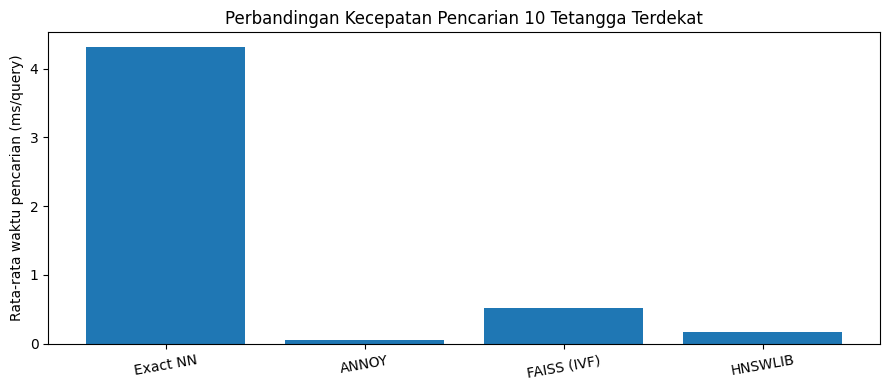

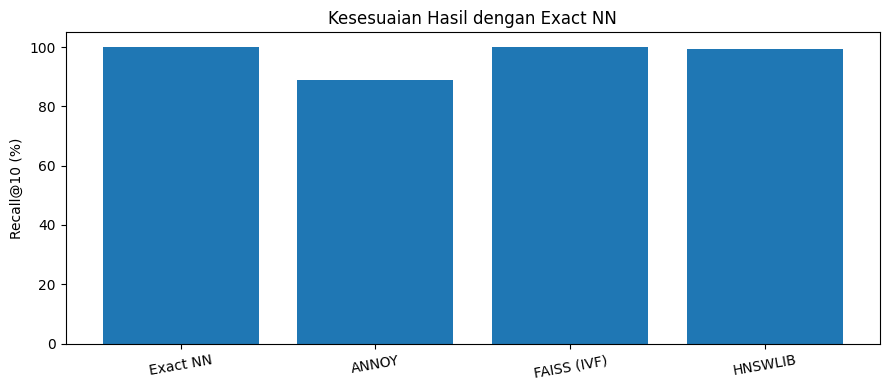

In [12]:
plt.figure(figsize=(9, 4))
plt.bar(tabel['Algoritma'], tabel['Rata-rata pencarian (ms/query)'])
plt.ylabel('Rata-rata waktu pencarian (ms/query)')
plt.title('Perbandingan Kecepatan Pencarian 10 Tetangga Terdekat')
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('grafik_waktu_lab2.png', dpi=160)
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(tabel['Algoritma'], tabel['Recall@10 (%)'])
plt.ylabel('Recall@10 (%)')
plt.ylim(0, 105)
plt.title('Kesesuaian Hasil dengan Exact NN')
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('grafik_recall_lab2.png', dpi=160)
plt.show()

In [13]:
kolom_judul = next((c for c in ['track_name', 'song', 'title', 'name'] if c in df.columns), None)
kolom_artis = next((c for c in ['artist', 'artists', 'track_artist'] if c in df.columns), None)

def info_lagu(pos_df):
    potongan = [f'baris {pos_df}']
    if kolom_judul:
        potongan.append(str(df.iloc[pos_df][kolom_judul])[:60])
    if kolom_artis:
        potongan.append(str(df.iloc[pos_df][kolom_artis])[:45])
    return ' | '.join(potongan)

print('Lagu query pertama:', info_lagu(indeks_query[0]))
for nama, jawaban in semua_tetangga.items():
    print(f'\n{nama} — 10 tetangga terdekat:')
    for urut, indeks_lokal in enumerate(jawaban[0], 1):
        print(f' {urut:2d}. {info_lagu(indeks_database[indeks_lokal])}')

Lagu query pertama: baris 19313 | A' - You're Adorable | Perry Como

Exact NN — 10 tetangga terdekat:
  1. baris 11035 | A - You're Adorable (with The Fontane Sisters) - Remastered | Perry Como, The Fontane Sisters
  2. baris 25954 | After You've Gone | Ruth Etting
  3. baris 16427 | A Primeira Vez | Jane Monheit
  4. baris 12928 | A Florida Cracker Christmas | 4 Star View
  5. baris 16004 | A Paixão (Segundo Nicolau Da Viola) | Rui Veloso
  6. baris 12939 | A Foggy Day | Fred Astaire
  7. baris 16191 | A Picture Of Me (Without You) | George Jones
  8. baris 28306 | Ain't Misbehavin' | Ike Moriz
  9. baris 14226 | A Little At A Time | Norah Jones
 10. baris 1364 | (I Love You) For Sentimental Reasons | Nat King Cole Trio

ANNOY — 10 tetangga terdekat:
  1. baris 11035 | A - You're Adorable (with The Fontane Sisters) - Remastered | Perry Como, The Fontane Sisters
  2. baris 16427 | A Primeira Vez | Jane Monheit
  3. baris 12928 | A Florida Cracker Christmas | 4 Star View
  4. baris 1600

saya menggunakan 30.000 data lagu Spotify. Sebanyak 30 data digunakan untuk pengujian pencarian, sedangkan 29.970 data lainnya menjadi database. Dari hasil yang diperoleh, ANNOY memiliki waktu pencarian paling cepat, yaitu 0,0457 ms/query. Namun, hasil pencariannya belum semuanya sama dengan Exact NN karena nilai recall-nya 89%. Sementara itu, FAISS menghasilkan recall 100%, tetapi membutuhkan waktu pencarian lebih lama. Dari percobaan ini, saya memahami bahwa algoritma yang paling cepat belum tentu menghasilkan kecocokan pencarian yang paling tinggi.